# DATA 245 | Person 2 — Model comparison and threshold tuning

**Classical ML only.** Reuses `src/data.py`, `src/features.py`, `src/metrics.py`, and adds `src/model_comparison.py`. Never evaluates the reserved final 20%.

**Evaluation protocol:** candidates chosen using the last 20% of the training portion; candidate selected and refitted on the complete training portion; development records used for model comparison and F1 threshold tuning. Consequently, development F1 is *optimistically tuned* and must not be called held-out test performance. Economic-feature arm is an exploratory sensitivity test, not an approved deployment specification.

In [1]:
import sys
from pathlib import Path
p = Path.cwd().resolve()
if (p / 'src').exists():
    root = p
elif (p.parent / 'src').exists():
    root = p.parent
else:
    raise FileNotFoundError('Run this notebook from project root or notebooks/ after extracting the ZIP.')
sys.path.insert(0, str(root))
from src.data import load_dataset, chronological_split
from src.model_comparison import train_comparison, shortlist, FEATURE_SETS, top_features
from src.settings import RAW_DATA_PATH
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print('Project root:', root)
print('Dataset:', RAW_DATA_PATH)
assert RAW_DATA_PATH.exists(), 'Place bank-additional-full.csv in data/raw/ first.'


Project root: /mnt/data/work_person2/ML-drift-project-main
Dataset: /mnt/data/work_person2/ML-drift-project-main/data/raw/bank-additional-full.csv


## 1. Chronological partition (never touch reserved stream)
The last 20% is split off but **not inspected, fitted, predicted, or evaluated** by this notebook.

In [2]:
all_data = load_dataset()
train, dev, reserved_stream = chronological_split(all_data)
assert (len(train), len(dev), len(reserved_stream)) == (24712, 8238, 8238)
print('Training records:', len(train), 'Development records:', len(dev))
print('Reserved records:', len(reserved_stream), '(NOT evaluated)')
print('Train YES share:', round((train['y']=='yes').mean(), 4))
print('Dev YES share:', round((dev['y']=='yes').mean(), 4))


Training records: 24712 Development records: 8238
Reserved records: 8238 (NOT evaluated)
Train YES share: 0.0481
Dev YES share: 0.1107


## 2. Models + economic-feature sensitivity test
Four classical models × two feature sets; small parameter choices compared on a chronological training-only holdout.

*Baseline features*: the original ten provisionally available features. *Economic arm*: those ten plus five macroeconomic indicators. Economic-feature availability is unresolved, so this arm **must not** automatically be promoted into production or the main experiment.

In [3]:
results, fitted_models = train_comparison(train, dev)
display(results[['feature_set','model','pr_auc','random_pr_auc','roc_auc','f1','precision','recall','tp','fp','fn','tn','threshold','score_type','training_seconds']].round(4))


baseline_10               Logistic Regression  dev AP 0.1786 F1 0.244 TP 352 FP 1626


baseline_10               Decision Tree        dev AP 0.1271 F1 0.211 TP 853 FP 6312


baseline_10               Random Forest        dev AP 0.1336 F1 0.217 TP 622 FP 4203


baseline_10               Linear SVM           dev AP 0.1619 F1 0.228 TP 363 FP 1913


baseline_plus_economic_15 Logistic Regression  dev AP 0.0942 F1 0.209 TP 720 FP 5246


baseline_plus_economic_15 Decision Tree        dev AP 0.1037 F1 0.199 TP 912 FP 7326


baseline_plus_economic_15 Random Forest        dev AP 0.1155 F1 0.206 TP 775 FP 5852


baseline_plus_economic_15 Linear SVM           dev AP 0.0945 F1 0.205 TP 691 FP 5153


,feature_set,model,pr_auc,random_pr_auc,roc_auc,f1,precision,recall,tp,fp,fn,tn,threshold,score_type,training_seconds
0,baseline_10,Logistic Regression,0.1786,0.1107,0.6059,0.2436,0.1780,0.3860,352,1626,560,5700,0.5291,probability,0.260
1,baseline_10,Linear SVM,0.1619,0.1107,0.5761,0.2277,0.1595,0.3980,363,1913,549,5413,0.0506,margin,0.200
2,baseline_10,Random Forest,0.1336,0.1107,0.5616,0.2168,0.1289,0.6820,622,4203,290,3123,0.0472,probability,0.819
3,baseline_10,Decision Tree,0.1271,0.1107,0.5577,0.2112,0.1191,0.9353,853,6312,59,1014,0.0377,probability,0.153
4,baseline_plus_economic_15,Random Forest,0.1155,0.1107,0.5335,0.2056,0.1169,0.8498,775,5852,137,1474,0.1983,probability,0.917
5,baseline_plus_economic_15,Decision Tree,0.1037,0.1107,0.4712,0.1993,0.1107,1.0000,912,7326,0,0,0.0000,probability,0.149
6,baseline_plus_economic_15,Linear SVM,0.0945,0.1107,0.4594,0.2046,0.1182,0.7577,691,5153,221,2173,-3.6312,margin,0.494
7,baseline_plus_economic_15,Logistic Regression,0.0942,0.1107,0.4645,0.2094,0.1207,0.7895,720,5246,192,2080,0.0000,probability,0.112


## 3. Direct answer to the TA: caught subscribers vs false alarms
The thresholds maximize development F1. These counts are **development tuned**, not independently tested. Linear SVM uses margin scores rather than calibrated probabilities.

,feature_set,model,tp,fp,fn,tn,precision,recall,f1,threshold
0,baseline_10,Logistic Regression,352,1626,560,5700,0.1780,0.3860,0.2436,0.5291
1,baseline_10,Linear SVM,363,1913,549,5413,0.1595,0.3980,0.2277,0.0506
2,baseline_10,Random Forest,622,4203,290,3123,0.1289,0.6820,0.2168,0.0472
3,baseline_10,Decision Tree,853,6312,59,1014,0.1191,0.9353,0.2112,0.0377
4,baseline_plus_economic_15,Random Forest,775,5852,137,1474,0.1169,0.8498,0.2056,0.1983
5,baseline_plus_economic_15,Decision Tree,912,7326,0,0,0.1107,1.0000,0.1993,0.0000
6,baseline_plus_economic_15,Linear SVM,691,5153,221,2173,0.1182,0.7577,0.2046,-3.6312
7,baseline_plus_economic_15,Logistic Regression,720,5246,192,2080,0.1207,0.7895,0.2094,0.0000


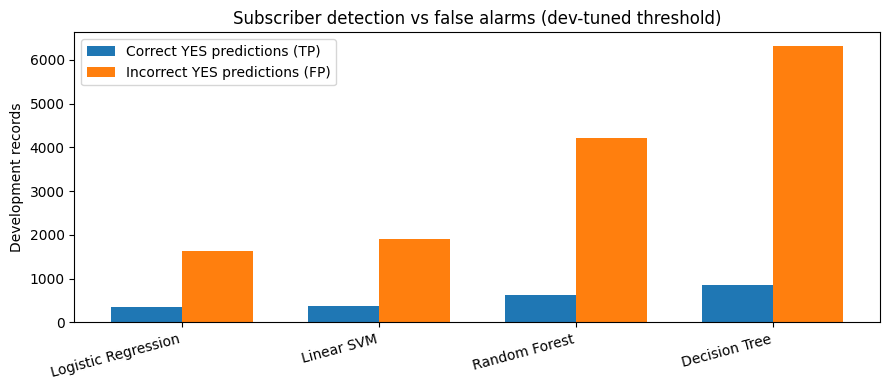

In [4]:
display(results[['feature_set','model','tp','fp','fn','tn','precision','recall','f1','threshold']].round(4))
fig, ax = plt.subplots(figsize=(9,4))
base = results.query("feature_set == 'baseline_10'")
pos = np.arange(len(base))
ax.bar(pos-0.18, base['tp'], width=.36, label='Correct YES predictions (TP)')
ax.bar(pos+0.18, base['fp'], width=.36, label='Incorrect YES predictions (FP)')
ax.set_xticks(pos, base['model'], rotation=15, ha='right')
ax.set_ylabel('Development records'); ax.legend(); ax.set_title('Subscriber detection vs false alarms (dev-tuned threshold)')
fig.tight_layout(); plt.show()


## 4. Compare feature sets
No improvement is guaranteed. Economic variables can drift strongly and may not have been available when the hypothetical prediction was made.

feature_set,baseline_10,baseline_plus_economic_15
model,,
Decision Tree,0.1271,0.1037
Linear SVM,0.1619,0.0945
Logistic Regression,0.1786,0.0942
Random Forest,0.1336,0.1155


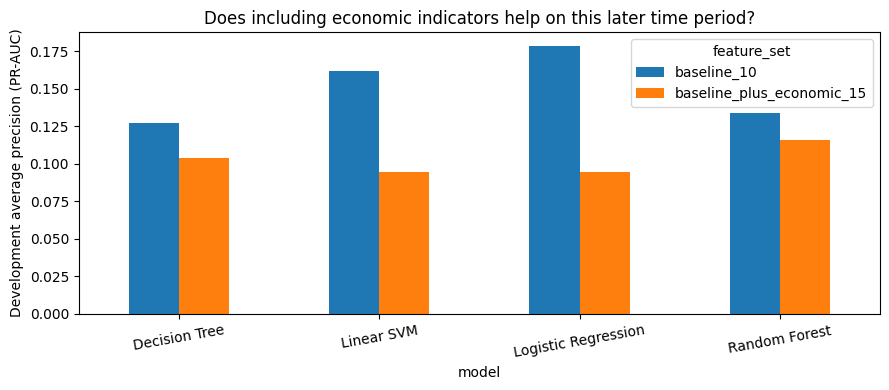

In [5]:
comparison = results.pivot(index='model', columns='feature_set', values='pr_auc')
display(comparison.round(4))
comparison.plot(kind='bar', figsize=(9,4), ylabel='Development average precision (PR-AUC)', rot=10,
                title='Does including economic indicators help on this later time period?')
plt.tight_layout(); plt.show()


## 5. Provisional shortlist and important features
The shortlist is a **recommendation based on development data**. Person 3 should not select models using the reserved stream. Coefficients/impurity importance explain model mechanics, **not causality**.

In [6]:
selected = shortlist(results, n=2)
display(selected[['feature_set','model','pr_auc','f1','precision','recall','tp','fp','threshold','score_type']].round(4))
for _, r in selected.iterrows():
    print('\n', r['model'], '/', r['feature_set'])
    display(top_features(fitted_models[(r['feature_set'],r['model'])], FEATURE_SETS[r['feature_set']], n=12))


,feature_set,model,pr_auc,f1,precision,recall,tp,fp,threshold,score_type
0,baseline_10,Logistic Regression,0.1786,0.2436,0.1780,0.386,352,1626,0.5291,probability
1,baseline_10,Linear SVM,0.1619,0.2277,0.1595,0.398,363,1913,0.0506,margin



 Logistic Regression / baseline_10


,feature,importance
0,categorical__marital_unknown,0.670979
1,categorical__education_illiterate,-0.532950
2,passthrough__pdays_is_999,-0.522587
3,categorical__job_housemaid,-0.483324
4,categorical__poutcome_success,0.394985
5,categorical__poutcome_failure,-0.366234
6,categorical__job_student,0.361451
7,categorical__job_retired,0.350504
8,categorical__marital_divorced,-0.302283
9,categorical__job_unemployed,-0.299687



 Linear SVM / baseline_10


,feature,importance
0,categorical__education_illiterate,-0.816465
1,categorical__default_yes,-0.607763
2,imputed__pdays_days,0.453250
3,passthrough__pdays_is_999,-0.373823
4,passthrough__previous,-0.292243
5,categorical__poutcome_nonexistent,-0.287386
6,categorical__marital_divorced,-0.280690
7,categorical__job_housemaid,-0.274280
8,categorical__marital_married,-0.259298
9,categorical__housing_unknown,-0.252204


## 6. Save handoff artifacts
Results CSV + a provisional shortlist JSON are written under `results/`. Model objects are **not** automatically committed. Retraining should refit the selected model and preprocessing only on labels that are already available. Remember: Linear SVM cutoffs are **margin thresholds**, not probabilities.

In [7]:
import json
outdir = root / 'results'; outdir.mkdir(exist_ok=True)
results.to_csv(outdir/'05_models_development_results.csv', index=False)
selected.to_csv(outdir/'05_models_shortlist.csv', index=False)
with open(outdir/'05_models_handoff.json','w') as f:
    json.dump({'status':'provisional','dataset':'bank-additional-full.csv',
               'split':'60/20/20 chronological; reserved stream unused',
               'threshold_tuning':'maximize F1 on development (optimistically tuned)',
               'economic_features':'sensitivity arm only; availability unresolved',
               'shortlist':[{'model':row['model'],'feature_set':row['feature_set'],
                             'decision_threshold':float(row['threshold']),
                             'score_type':row['score_type'],'config_index':int(row['selected_config'])}
                            for _,row in selected.iterrows()]},f,indent=2)
print('Saved results to', outdir)


Saved results to /mnt/data/work_person2/ML-drift-project-main/results


## Interpretation / limitations
- The first 60% trains the models; the next 20% is used for choosing thresholds and evaluating preliminary model behavior; the last 20% remains reserved.
- Threshold tuning on development makes development F1 optimistic. Report results on the future stream **only in the preregistered final experiment**, not here.
- A low F1 and many false positives may reflect low prevalence, weak predictor signal, temporal shifts, and imperfect thresholds. We have not established a causal explanation.
- The economic indicators are exploratory pending a documented prediction-time availability decision.
- During retraining, avoid using future labels and reuse the same score conventions for each model.
- Keep this notebook and the artifacts separate from the other students’ files until they have reviewed them.